In [28]:
import pandas as pd
import matplotlib.pyplot as plt
import os
import seaborn as sns
import numpy as np

## Load Data

In [ ]:
# Load data
data_folder = r'C:\Users\esteb\OneDrive - Universidad de los andes\Documentos\ANDES\Noveno Semestre\PA-RSPPs\PA-Experiments\output_new'

#Chicago Sketch
CS_full_experiment = pd.read_csv(os.path.join(data_folder, 'CS_full_experiment.csv'))
CS_bounds_experiment = pd.read_csv(os.path.join(data_folder, 'CS_bounds_experiment.csv'))
CS_feasibility_experiment = pd.read_csv(os.path.join(data_folder, 'CS_feasibility_experiment.csv'))
CS_full_pruning = pd.read_csv(os.path.join(data_folder, 'CS_full_pruning.csv'))

# Chicago Regional
CR_full_experiment = pd.read_csv(os.path.join(data_folder, 'CR_full_experiment.csv'))
CR_bounds_experiment = pd.read_csv(os.path.join(data_folder, 'CR_bounds_experiment.csv'))
CR_feasibility_experiment = pd.read_csv(os.path.join(data_folder, 'CR_feasibility_experiment.csv'))
CR_full_pruning = pd.read_csv(os.path.join(data_folder, 'CR_full_pruning.csv'))
CR_bounds_timeout = pd.read_csv(os.path.join(data_folder, 'CR_timeout_experiment.csv'))

# Sydney
SY_full_experiment = pd.read_csv(os.path.join(data_folder, 'SY_full_experiment.csv'))
SY_bounds_experiment = pd.read_csv(os.path.join(data_folder, 'SY_bounds_experiment.csv'))
SY_feasibility_experiment = pd.read_csv(os.path.join(data_folder, 'SY_feasibility_experiment.csv'))
SY_full_pruning = pd.read_csv(os.path.join(data_folder, 'SY_full_pruning.csv'))
SY_bounds_timeout = pd.read_csv(os.path.join(data_folder, 'SY_timeout_experiment.csv'))

# Define colors
pastel_green = "#79b385"  # Darker shade of pastel green
pastel_blue = "#6a9db5"   # Darker shade of pastel blue
pastel_orange = "#d6a65b"  # Darker shade of pastel orange

## SARP

Mean:  6.77e-03---- 1.89e-01---- 3.66e-01----
Median:  6.06e-03---- 1.71e-01---- 3.41e-01----
Std:  3.96e-03---- 4.63e-02---- 6.29e-02----


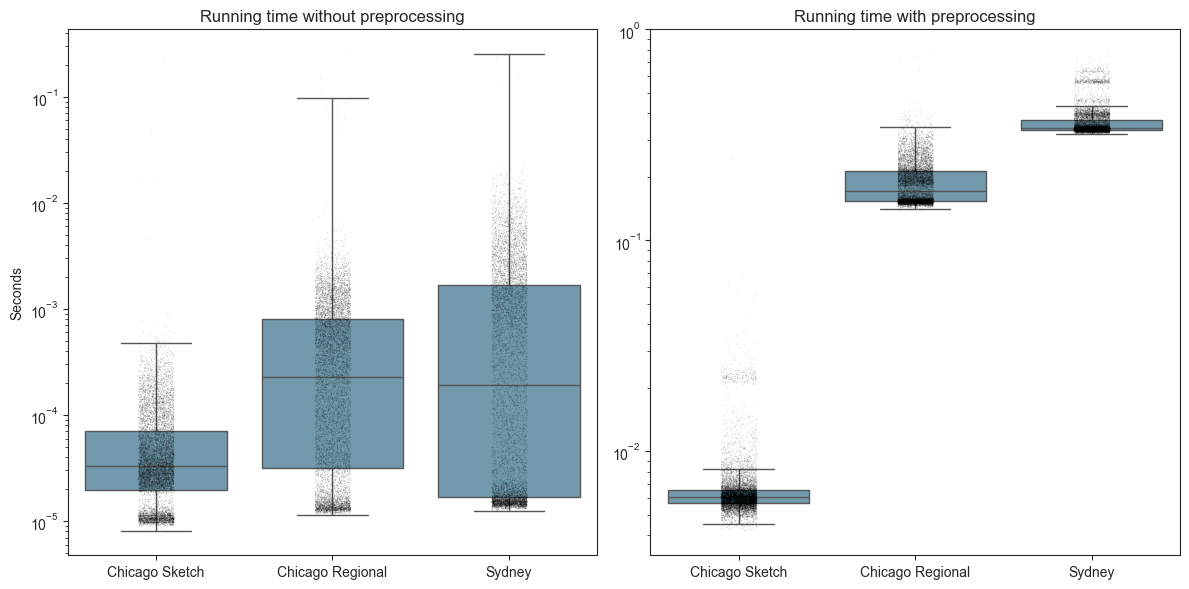

In [34]:
# Extract values
CS_raw = CS_full_experiment["elapsed_time"].values
CR_raw = CR_full_experiment["elapsed_time"].values
SY_raw = SY_full_experiment["elapsed_time"].values

#check that there was not timeout
assert np.all(CS_full_experiment["timeout"] == False), "CS experiment timed out"
assert np.all(CR_full_experiment["timeout"] == False), "CR experiment timed out"
assert np.all(SY_full_experiment["timeout"] == False), "SY experiment timed out"

CS_prep = CS_full_experiment["preprocessing_time"].values + CS_raw
CR_prep = CR_full_experiment["preprocessing_time"].values + CR_raw
SY_prep = SY_full_experiment["preprocessing_time"].values + SY_raw
print("Mean: ", 
      f"{CS_prep.mean():.2e}----", 
      f"{CR_prep.mean():.2e}----", 
      f"{SY_prep.mean():.2e}----")
print("Median: ",
      f"{np.median(CS_prep):.2e}----", 
      f"{np.median(CR_prep):.2e}----", 
      f"{np.median(SY_prep):.2e}----")
print("Std: ",
        f"{CS_prep.std():.2e}----", 
        f"{CR_prep.std():.2e}----", 
        f"{SY_prep.std():.2e}----")

# Create DataFrames
df_raw = pd.DataFrame({
    "Time": list(CS_raw) + list(CR_raw) + list(SY_raw),
    "Network": ["Chicago Sketch"] * len(CS_raw) + ["Chicago Regional"] * len(CR_raw) + ["Sydney"] * len(SY_raw)
})

df_prep = pd.DataFrame({
    "Time": list(CS_prep) + list(CR_prep) + list(SY_prep),
    "Network": ["Chicago Sketch"] * len(CS_prep) + ["Chicago Regional"] * len(CR_prep) + ["Sydney"] * len(SY_prep)
})

# Subplots with independent y-axes
fig, axes = plt.subplots(1, 2, figsize=(12, 6))  # No sharey

# Raw times plot
sns.boxplot(data=df_raw, x="Network", y="Time", log_scale=True,
            showfliers=False, color=pastel_blue, ax=axes[0])
sns.stripplot(data=df_raw, x="Network", y="Time", color='black',
              alpha=0.1, size=1, jitter=True, log_scale=True, ax=axes[0])
axes[0].set_title("Running time without preprocessing")
axes[0].set_ylabel("Seconds", fontsize=10)

# Prepended times plot
sns.boxplot(data=df_prep, x="Network", y="Time", log_scale=True,
            showfliers=False, color=pastel_blue, ax=axes[1])
sns.stripplot(data=df_prep, x="Network", y="Time", color='black',
              alpha=0.1, size=1, jitter=True, log_scale=True, ax=axes[1])
axes[1].set_title("Running time with preprocessing")
axes[1].set_ylabel("")
axes[1].set_xlabel("")
axes[0].set_xlabel("")

plt.tight_layout()
plt.show()


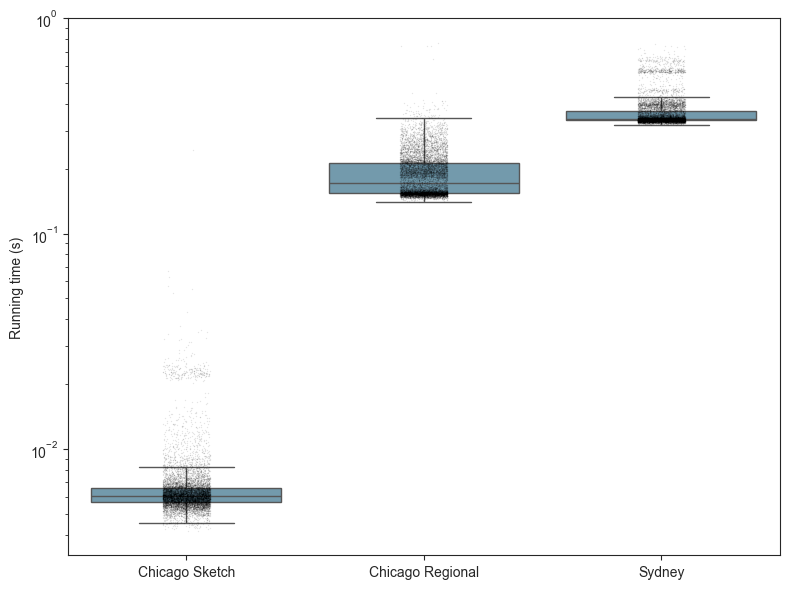

In [33]:
fig, ax = plt.subplots(1, 1, figsize=(8, 6)) # Adjusted figsize for single plot

# Prepended times plot on the single axis
sns.boxplot(data=df_prep, x="Network", y="Time", log_scale=True,
            showfliers=False, color=pastel_blue, ax=ax)
sns.stripplot(data=df_prep, x="Network", y="Time", color='black',
              alpha=0.1, size=1, jitter=True, log_scale=True, ax=ax)

# Set title and labels for the single plot
ax.set_ylabel("Running time (s)", fontsize=10)
ax.set_xlabel("", fontsize=10)

plt.tight_layout()
plt.show()

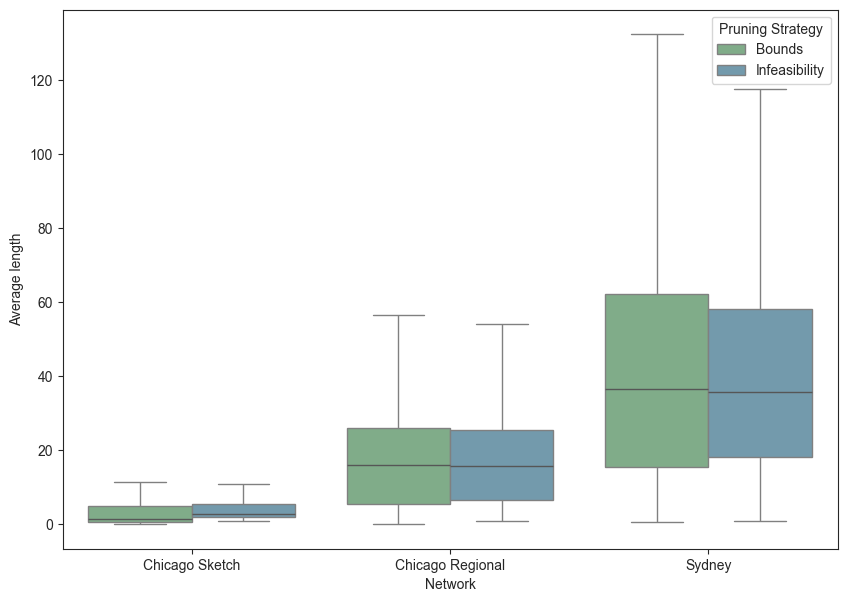

In [38]:
CS_bounds = CS_full_pruning['length_pruned_by_bounds'].dropna()
CR_bounds = CR_full_pruning['length_pruned_by_bounds'].dropna()
SY_bounds = SY_full_pruning['length_pruned_by_bounds'].dropna()

CS_feasibility = CS_full_pruning['length_pruned_by_feasibility'].dropna()
CR_feasibility = CR_full_pruning['length_pruned_by_feasibility'].dropna()
SY_feasibility = SY_full_pruning['length_pruned_by_feasibility'].dropna()

dataframes = [
    pd.DataFrame({'Average length': CS_bounds, 'Network': 'Chicago Sketch', 'Pruning Strategy': 'Bounds'}),
    pd.DataFrame({'Average length': CR_bounds, 'Network': 'Chicago Regional', 'Pruning Strategy': 'Bounds'}),
    pd.DataFrame({'Average length': SY_bounds, 'Network': 'Sydney', 'Pruning Strategy': 'Bounds'}),
    pd.DataFrame({'Average length': CS_feasibility, 'Network': 'Chicago Sketch', 'Pruning Strategy': 'Infeasibility'}),
    pd.DataFrame({'Average length': CR_feasibility, 'Network': 'Chicago Regional', 'Pruning Strategy': 'Infeasibility'}),
    pd.DataFrame({'Average length': SY_feasibility, 'Network': 'Sydney', 'Pruning Strategy': 'Infeasibility'})
]

# Combine all DataFrames into a single one
df_long = pd.concat(dataframes, ignore_index=True)

sns.set_style("ticks")
plt.figure(figsize=(10, 7)) # Set the figure size

# Define custom colors to match the image
custom_palette = {
    'Bounds': pastel_green,
    'Infeasibility': pastel_blue
}

# Generate the box plot
ax = sns.boxplot(
    data=df_long,
    x='Network',
    y='Average length',
    hue='Pruning Strategy',
    palette=custom_palette,
    boxprops={'edgecolor': 'gray'},
    whiskerprops={'color': 'gray'},
    capprops={'color': 'gray'},
    showfliers=False
)
# do not show outliers


In [39]:
print(f"Chicago Sketch. Bounds: {CS_bounds.mean()}, Infeasibility: {CS_feasibility.mean()}")
print(f"Chicago Regional. Bounds: {CR_bounds.mean()}, Infeasibility: {CR_feasibility.mean()}")
print(f"Sydney. Bounds: {SY_bounds.mean()}, Infeasibility: {SY_feasibility.mean()}")


Chicago Sketch. Bounds: 3.1188480978983772, Infeasibility: 4.123028640001769
Chicago Regional. Bounds: 17.08996554275722, Infeasibility: 17.280611847175972
Sydney. Bounds: 42.458758475152585, Infeasibility: 40.895414425843036


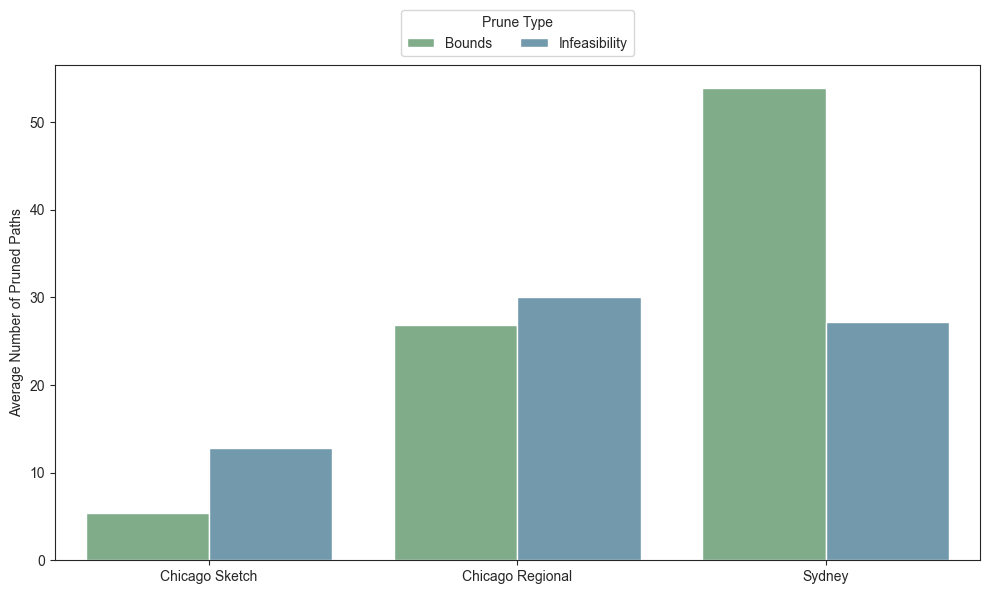

In [40]:
data = {
    'Network': ['Chicago Sketch', 'Chicago Sketch', 'Chicago Regional', 'Chicago Regional', 'Sydney', 'Sydney'],
    'Metric': ['Bounds', 'Infeasibility', 'Bounds', 'Infeasibility', 'Bounds', 'Infeasibility'],
    'Value': [
        CS_full_experiment['pruned_by_bounds'].mean(),
        CS_full_experiment['pruned_by_feasibility'].mean(),
        CR_full_experiment['pruned_by_bounds'].mean(),
        CR_full_experiment['pruned_by_feasibility'].mean(),
        SY_full_experiment['pruned_by_bounds'].mean(),
        SY_full_experiment['pruned_by_feasibility'].mean()
    ]
}

df = pd.DataFrame(data)

color_palette = {
    'Bounds': pastel_green,
    'Infeasibility': pastel_blue
}

plt.figure(figsize=(10, 6)) # Adjust figure size as needed
sns.barplot(x='Network', y='Value', hue='Metric', data=df, palette=color_palette)
plt.ylabel('Average Number of Pruned Paths', fontsize=10)
plt.xlabel('', fontsize=10)
plt.legend(title='Prune Type', loc="upper center", ncol=2, bbox_to_anchor=(0.5, 1.125))
plt.tight_layout() # Adjust layout to prevent labels from overlapping
plt.show()

In [41]:
CS_bounds_percent = (CS_full_experiment['pruned_by_bounds'] / (CS_full_experiment['pruned_by_bounds'] + CS_full_experiment['pruned_by_feasibility'])).mean() * 100
CS_inf_percent = (CS_full_experiment['pruned_by_feasibility'] / (CS_full_experiment['pruned_by_bounds'] + CS_full_experiment['pruned_by_feasibility'])).mean() * 100

CR_bounds_percent = (CR_full_experiment['pruned_by_bounds'] / (CR_full_experiment['pruned_by_bounds'] + CR_full_experiment['pruned_by_feasibility'])).mean() * 100
CR_inf_percent = (CR_full_experiment['pruned_by_feasibility'] / (CR_full_experiment['pruned_by_bounds'] + CR_full_experiment['pruned_by_feasibility'])).mean() * 100

SY_bounds_percent = (SY_full_experiment['pruned_by_bounds'] / (SY_full_experiment['pruned_by_bounds'] + SY_full_experiment['pruned_by_feasibility'])).mean() * 100
SY_inf_percent = (SY_full_experiment['pruned_by_feasibility'] / (SY_full_experiment['pruned_by_bounds'] + SY_full_experiment['pruned_by_feasibility'])).mean() * 100

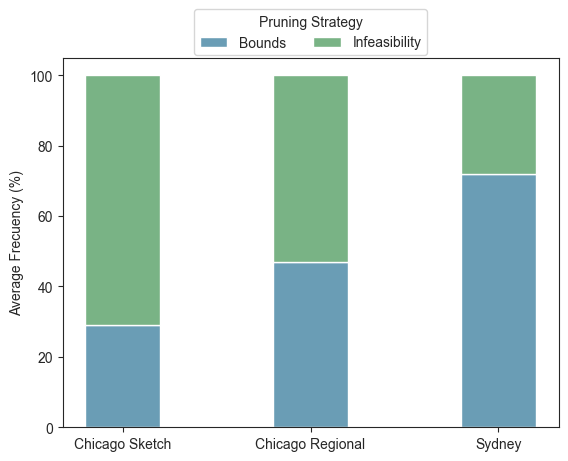

Chicago Sketch
Bounds:  29.172718900726935
Infeasibility:  70.82728109927308
Chicago Regional
Bounds:  46.84611017393803
Infeasibility:  53.15388982606196
Sydney
Bounds:  71.82376525469091
Infeasibility:  28.17623474530909


In [42]:
fig, ax = plt.subplots()

sns.barplot()

bar_width = 0.4

ax.bar("Chicago Sketch", CS_bounds_percent, label="Bounds", color=pastel_blue, width=bar_width)
ax.bar("Chicago Sketch", CS_inf_percent, bottom=CS_bounds_percent, label="Infeasibility", color=pastel_green, width=bar_width)

ax.bar("Chicago Regional", CR_bounds_percent, color=pastel_blue, width=bar_width)
ax.bar("Chicago Regional", CR_inf_percent, bottom=CR_bounds_percent, color=pastel_green, width=bar_width)

ax.bar("Sydney", SY_bounds_percent, color=pastel_blue, width=bar_width)
ax.bar("Sydney", SY_inf_percent, bottom=SY_bounds_percent, color=pastel_green, width=bar_width)

handles, labels = ax.get_legend_handles_labels()
unique_labels = dict(zip(labels, handles))  # Use a dictionary to keep unique labels
ax.legend(unique_labels.values(), unique_labels.keys(), title="Pruning Strategy", loc="upper center", ncol=2, bbox_to_anchor=(0.5, 1.15))

plt.ylabel("Average Frecuency (%)")
plt.show()

#Print the values for each bar graph
print("Chicago Sketch")
print("Bounds: ", CS_bounds_percent)
print("Infeasibility: ", CS_inf_percent)
print("Chicago Regional")
print("Bounds: ", CR_bounds_percent)
print("Infeasibility: ", CR_inf_percent)
print("Sydney")
print("Bounds: ", SY_bounds_percent)
print("Infeasibility: ", SY_inf_percent)


## SDRSPP

In [43]:
## Load data
data_folder = r'C:\Users\esteb\OneDrive - Universidad de los andes\Documentos\ANDES\Noveno Semestre\PA-RSPPs\PA-Experiments\output_new'

def load_csvs_with_substring(directory, substring):
    dataframes = []
    filenames = []

    for file in os.listdir(directory):
        if file.endswith(".csv") and substring in file:
            full_path = os.path.join(directory, file)
            df = pd.read_csv(full_path)
            dataframes.append(df)
            filenames.append(file)

    return dataframes, filenames

time_sdrspp, _ = load_csvs_with_substring(data_folder, 'time_sdrsp')
nondominated_sdrspp, _ = load_csvs_with_substring(data_folder, 'nondominated_sdrsp')

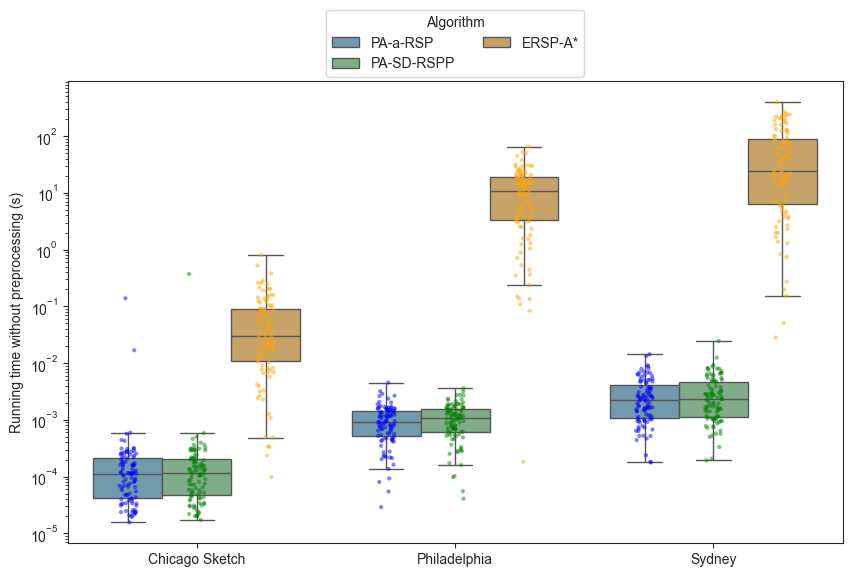

Mean Running Time for Each Algorithm by Network:
          Network   Algorithm      Time
0  Chicago Sketch     ERSP-A*  7.38e-02
1  Chicago Sketch  PA-SD-RSPP  3.85e-03
2  Chicago Sketch    PA-a-RSP  1.69e-03
3    Philadelphia     ERSP-A*  1.33e+01
4    Philadelphia  PA-SD-RSPP  1.15e-03
5    Philadelphia    PA-a-RSP  1.06e-03
6          Sydney     ERSP-A*  6.39e+01
7          Sydney  PA-SD-RSPP  3.27e-03
8          Sydney    PA-a-RSP  2.99e-03


In [44]:
# remove certain columns of the list
time_sdrspp_noprep = [df.drop(columns=[col for col in df.columns if 'pt' in col]) for df in time_sdrspp]

melted_data_list = [
    pd.melt(df, var_name="Network", value_name="Time")
    for df in time_sdrspp_noprep
]
melted_data = pd.concat(melted_data_list, ignore_index=True)
melted_data.dropna(inplace=True)

melted_data["Algorithm"] = melted_data["Network"].apply(
    lambda x: "ERSP-A*" if "ERSPA" in x else ("PA-SD-RSPP" if "dominance" in x else "PA-a-RSP")
)
melted_data["Network"] = melted_data["Network"].replace({
    "CS_t": "Chicago Sketch",
    "CS_t_ERSPA": "Chicago Sketch",
    "CS_t_dominance": "Chicago Sketch",
    "PH_t": "Philadelphia",
    "PH_t_ERSPA": "Philadelphia",
    "PH_t_dominance": "Philadelphia",
    "SY_t": "Sydney",
    "SY_t_ERSPA": "Sydney", 
    "SY_t_dominance": "Sydney",
})

fig, ax = plt.subplots(figsize=(10, 6))


boxplot = sns.boxplot(
    data=melted_data,
    x="Network",
    y="Time",
    hue="Algorithm",
    palette=[pastel_blue, pastel_green, pastel_orange],
    showfliers=False,
    ax=ax,
    log_scale=True)

# Adding strip plot for individual data points
sns.stripplot(
    data=melted_data,
    x="Network",
    y="Time",
    hue="Algorithm",
    palette=["blue", "green", "orange"],
    dodge=True,
    alpha=0.5,
    size=3,
    jitter=True,
    log_scale=True,
    ax=ax,
    legend=False
)

ax.legend(title="Algorithm", loc="upper center", ncol=2, bbox_to_anchor=(0.5, 1.17))
ax.set_xlabel('')
boxplot.set_ylabel("Running time without preprocessing (s)", fontsize=10)
plt.show()

mean_values = melted_data.groupby(["Network", "Algorithm"])["Time"].mean().reset_index()
mean_values["Time"] = mean_values["Time"].apply(lambda x: "{:.2e}".format(x))
print("Mean Running Time for Each Algorithm by Network:")
print(mean_values)

In [45]:
for df in time_sdrspp:
    pt_cols = [col for col in df.columns if '_pt' in col]
    df = df[pt_cols]
    print(df.describe())

            CS_pt  CS_pt_dominance  CS_pt_ERSPA
count  100.000000       100.000000   100.000000
mean     0.005067         0.004871     0.000012
std      0.002276         0.002985     0.000003
min      0.003503         0.003456     0.000010
25%      0.004323         0.004040     0.000011
50%      0.004656         0.004328     0.000011
75%      0.004955         0.004673     0.000012
max      0.020333         0.028745     0.000039
            PH_pt  PH_pt_dominance  PH_pt_ERSPA
count  100.000000       100.000000   100.000000
mean     0.111636         0.113057     0.000215
std      0.032579         0.032240     0.000071
min      0.096357         0.096740     0.000162
25%      0.099582         0.099957     0.000187
50%      0.101640         0.102062     0.000196
75%      0.110594         0.108719     0.000219
max      0.377920         0.355895     0.000829
           SY_pt  SY_pt_dominance  SY_pt_ERSPA
count  99.000000        99.000000    99.000000
mean    0.252603         0.265660     0.00

In [46]:
time_sdrspp_summed = []

for df in time_sdrspp:
    pt_cols = [col for col in df.columns if '_pt' in col]
    t_cols = [col for col in df.columns if '_t' in col]

    # Normalize to base names (strip _pt or _t)
    pt_keys = {col.replace('_pt', ''): col for col in pt_cols}
    t_keys = {col.replace('_t', ''): col for col in t_cols}

    # Find common base names
    common_keys = set(pt_keys).intersection(t_keys)

    # Create new DataFrame with only the summed columns
    new_df = pd.DataFrame()
    for key in common_keys:
        new_df[key] = df[pt_keys[key]] + df[t_keys[key]]
    
    time_sdrspp_summed.append(new_df)

In [47]:
for i, df in enumerate(time_sdrspp_summed):
    print(df.describe())

         CS_ERSPA          CS  CS_dominance
count  100.000000  100.000000    100.000000
mean     0.073793    0.006756      0.008726
std      0.114125    0.014491      0.037245
min      0.000111    0.003522      0.003486
25%      0.010725    0.004458      0.004150
50%      0.029506    0.004790      0.004489
75%      0.091208    0.005115      0.004817
max      0.796746    0.147514      0.376247
       PH_dominance          PH    PH_ERSPA
count    100.000000  100.000000  100.000000
mean       0.114209    0.112695   13.258132
std        0.032443    0.032768   12.458551
min        0.097009    0.097401    0.000370
25%        0.100658    0.100260    3.310574
50%        0.103302    0.102253   10.886236
75%        0.110016    0.111208   19.402797
max        0.357393    0.379687   65.211863
       SY_dominance         SY    SY_ERSPA
count     99.000000  99.000000   99.000000
mean       0.268934   0.255597   63.915337
std        0.103143   0.077248   79.365143
min        0.223504   0.216155    0.

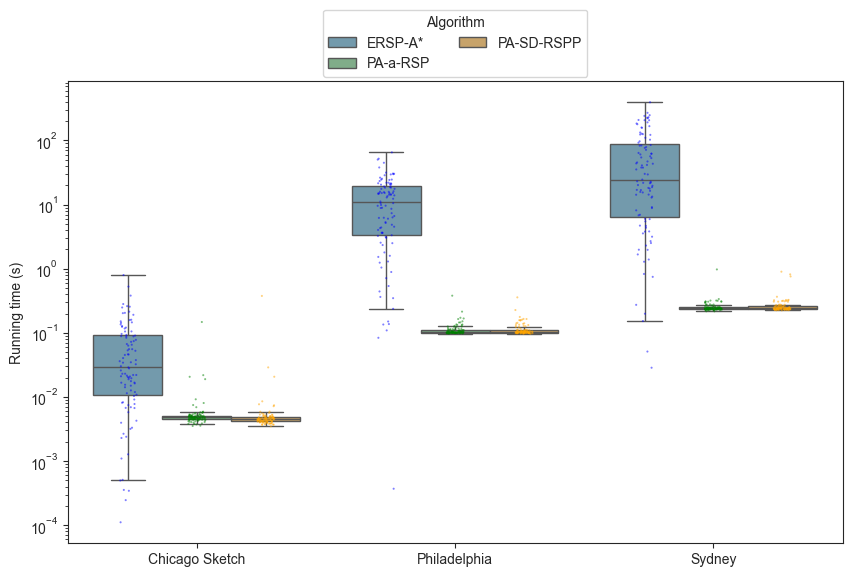

Mean Running Time for Each Algorithm by Network:
          Network   Algorithm      Time
0  Chicago Sketch     ERSP-A*  7.38e-02
1  Chicago Sketch  PA-SD-RSPP  8.73e-03
2  Chicago Sketch    PA-a-RSP  6.76e-03
3    Philadelphia     ERSP-A*  1.33e+01
4    Philadelphia  PA-SD-RSPP  1.14e-01
5    Philadelphia    PA-a-RSP  1.13e-01
6          Sydney     ERSP-A*  6.39e+01
7          Sydney  PA-SD-RSPP  2.69e-01
8          Sydney    PA-a-RSP  2.56e-01


In [52]:
melted_data_list = [
    pd.melt(df, var_name="Network", value_name="Time")
    for df in time_sdrspp_summed
]

melted_data = pd.concat(melted_data_list, ignore_index=True)
melted_data.dropna(inplace=True)

melted_data["Algorithm"] = melted_data["Network"].apply(
    lambda x: "ERSP-A*" if "ERSPA" in x else ("PA-SD-RSPP" if "dominance" in x else "PA-a-RSP")
)
melted_data["Network"] = melted_data["Network"].replace({
    "CS": "Chicago Sketch",
    "CS_ERSPA": "Chicago Sketch",
    "CS_dominance": "Chicago Sketch",
    "PH": "Philadelphia",
    "PH_ERSPA": "Philadelphia",
    "PH_dominance": "Philadelphia",
    "SY": "Sydney",
    "SY_ERSPA": "Sydney", 
    "SY_dominance": "Sydney",
})

fig, ax = plt.subplots(figsize=(10, 6))


boxplot = sns.boxplot(
    data=melted_data,
    x="Network",
    y="Time",
    hue="Algorithm",
    palette=[pastel_blue, pastel_green, pastel_orange],
    showfliers=False,
    ax=ax,
    log_scale=True
)

# Adding strip plot for individual data points
sns.stripplot(
    data=melted_data,
    x="Network",
    y="Time",
    hue="Algorithm",
    palette=["blue", "green", "orange"],
    dodge=True,
    alpha=0.5,
    size=1.5,
    jitter=True,
    log_scale=True,
    ax=ax,
    legend=False
)

ax.legend(title="Algorithm", loc="upper center", ncol=2, bbox_to_anchor=(0.5, 1.17))
ax.set_xlabel('')
boxplot.set_ylabel("Running time (s)", fontsize=10)
plt.show()

mean_values = melted_data.groupby(["Network", "Algorithm"])["Time"].mean().reset_index()
mean_values["Time"] = mean_values["Time"].apply(lambda x: "{:.2e}".format(x))
print("Mean Running Time for Each Algorithm by Network:")
print(mean_values)

In [53]:
print(nondominated_sdrspp[0].mean())
print(nondominated_sdrspp[1].mean())
print(nondominated_sdrspp[2].mean())

CS_n                0.27
CS_n_dominance      0.27
CS_n_ERSPA        302.44
dtype: float64
PH_n                 0.71
PH_n_dominance       0.71
PH_n_ERSPA        1364.18
dtype: float64
SY_n                0.888889
SY_n_dominance      0.888889
SY_n_ERSPA        963.343434
dtype: float64


c:\Users\esteb\.pyenv\pyenv-win\versions\3.10.11\lib\site-packages\numpy\lib\_function_base_impl.py:4653: RuntimeWarning: invalid value encountered in subtract
  diff_b_a = subtract(b, a)
c:\Users\esteb\.pyenv\pyenv-win\versions\3.10.11\lib\site-packages\numpy\lib\_function_base_impl.py:4653: RuntimeWarning: invalid value encountered in subtract
  diff_b_a = subtract(b, a)


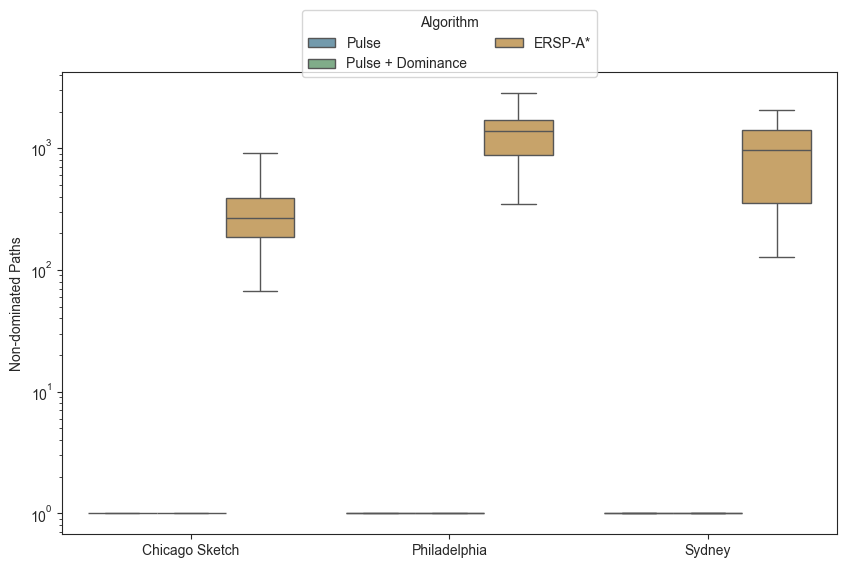

Mean Non-Dominated Paths for Each Algorithm by Network:
          Network          Algorithm NonDominatedPaths
0  Chicago Sketch            ERSP-A*          3.02e+02
1  Chicago Sketch              Pulse          2.70e-01
2  Chicago Sketch  Pulse + Dominance          2.70e-01
3    Philadelphia            ERSP-A*          1.36e+03
4    Philadelphia              Pulse          7.10e-01
5    Philadelphia  Pulse + Dominance          7.10e-01
6          Sydney            ERSP-A*          9.63e+02
7          Sydney              Pulse          8.89e-01
8          Sydney  Pulse + Dominance          8.89e-01


In [54]:
melted_data_list = [
    pd.melt(df, var_name="Network", value_name="NonDominatedPaths")
    for df in nondominated_sdrspp
]

melted_data = pd.concat(melted_data_list, ignore_index=True)

melted_data["Algorithm"] = melted_data["Network"].apply(
    lambda x: "ERSP-A*" if "ERSPA" in x else ("Pulse + Dominance" if "dominance" in x else "Pulse")
)
melted_data["Network"] = melted_data["Network"].replace({
    "CS_n": "Chicago Sketch",
    "CS_n_dominance": "Chicago Sketch",
    "CS_n_ERSPA": "Chicago Sketch",
    "PH_n": "Philadelphia",
    "PH_n_dominance": "Philadelphia",
    "PH_n_ERSPA": "Philadelphia",
    "SY_n": "Sydney",
    "SY_n_dominance": "Sydney",
    "SY_n_ERSPA": "Sydney"
})

fig, ax = plt.subplots(figsize=(10, 6))


boxplot = sns.boxplot(
    data=melted_data,
    x="Network",
    y="NonDominatedPaths",
    hue="Algorithm",
    palette=[pastel_blue, pastel_green, pastel_orange],
    showfliers=False,
    ax=ax,
    log_scale=True
)



ax.legend(title="Algorithm", loc="upper center", ncol=2, bbox_to_anchor=(0.5, 1.15))

ax.set_xlabel('')
boxplot.set_ylabel("Non-dominated Paths", fontsize=10)
plt.show()

mean_values = melted_data.groupby(["Network", "Algorithm"])["NonDominatedPaths"].mean().reset_index()
mean_values["NonDominatedPaths"] = mean_values["NonDominatedPaths"].apply(lambda x: "{:.2e}".format(x))
print("Mean Non-Dominated Paths for Each Algorithm by Network:")
print(mean_values)

#### REGRESSION

In [56]:
data_folder = r'C:\Users\esteb\OneDrive - Universidad de los andes\Documentos\ANDES\Noveno Semestre\PA-RSPPs\PA-Experiments\output_new'
regression = pd.read_csv(os.path.join(data_folder, 'regression.csv'))

In [57]:
import statsmodels.api as sm
import numpy as np
from statsmodels.stats.diagnostic import het_breuschpagan

len(regression)

22980

In [58]:
df = regression.copy()
nodes = {
    'SY': 33113,
    'CS': 933,
    'CR': 12982
}
df['Total_time'] = df['Elapsed_Time'] + df['Preprocessing_Time']
for network in nodes.keys():
    df.loc[df['Network'] == network, 'Nodes'] = nodes[network]

df_CS = df[df['Network'] == 'CS']
df_CR = df[df['Network'] == 'CR']
df_SY = df[df['Network'] == 'SY']

dfs = [df_CS, df_CR, df_SY]

for i, df in enumerate(dfs):
    for col in df.columns:
        if not pd.api.types.is_numeric_dtype(df[col]):
            continue
        q1 = df[col].quantile(0.25)
        q3 = df[col].quantile(0.75)
        iqr = q3 - q1
        lower_bound = q1 - 1.5 * iqr
        upper_bound = q3 + 1.5 * iqr
        df = df[(df[col] >= lower_bound) & (df[col] <= upper_bound)]

for i, df in enumerate(dfs):
    for col in df.columns:
        if not pd.api.types.is_numeric_dtype(df[col]):
            continue
        df[col + '_log'] = np.log(df[col])

df_all = pd.concat(dfs, ignore_index=True)
df_all.columns

Index(['Elapsed_Time', 'Preprocessing_Time', 'Time_Budget', 'Alpha', 'Gamma',
       'Rho', 'Max_Depth', 'Distance', 'Network', 'Total_time', 'Nodes',
       'Elapsed_Time_log', 'Preprocessing_Time_log', 'Time_Budget_log',
       'Alpha_log', 'Gamma_log', 'Rho_log', 'Max_Depth_log', 'Distance_log',
       'Total_time_log', 'Nodes_log'],
      dtype='object')

                            OLS Regression Results                            
Dep. Variable:       Elapsed_Time_log   R-squared:                       0.140
Model:                            OLS   Adj. R-squared:                  0.140
Method:                 Least Squares   F-statistic:                     934.4
Date:                Sat, 06 Sep 2025   Prob (F-statistic):               0.00
Time:                        11:38:25   Log-Likelihood:                -43184.
No. Observations:               22980   AIC:                         8.638e+04
Df Residuals:                   22975   BIC:                         8.642e+04
Df Model:                           4                                         
Covariance Type:            nonrobust                                         
                      coef    std err          t      P>|t|      [0.025      0.975]
-----------------------------------------------------------------------------------
const             -14.2087      0.081   -1

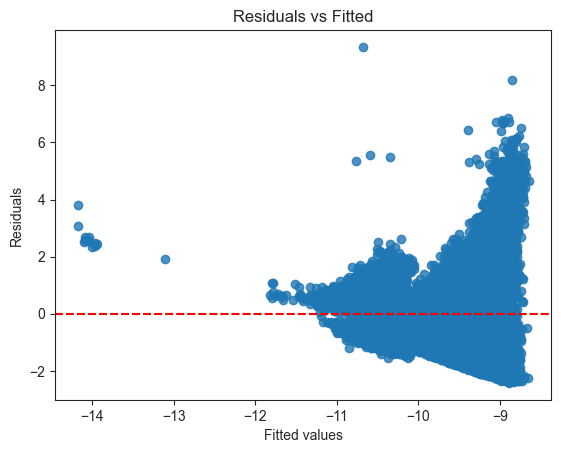

(np.float64(4491.355524922728), np.float64(0.0), np.float64(1395.3009551916919), np.float64(0.0))


In [65]:
# Design matrix
X = df_all[['Time_Budget_log',
       'Rho_log', 'Max_Depth_log', 'Nodes_log']]
X = sm.add_constant(X)  # Add intercept
y = df_all['Elapsed_Time_log']  # Dependent variable


# Regresión lineal
model = sm.OLS(y, X).fit()
print(model.summary())

residuals = model.resid
fitted_vals = model.fittedvalues

# Plot residuals vs fitted values
sns.residplot(x=fitted_vals, y=residuals)
plt.axhline(0, color='red', linestyle='--')
plt.title('Residuals vs Fitted')
plt.xlabel('Fitted values')
plt.ylabel('Residuals')
plt.show()

bp_test = het_breuschpagan(residuals, X)
print(bp_test)

In [66]:
ols_resid = model.resid
weights = 1 / (ols_resid ** 2 + 1e-6) 

model_wls = sm.WLS(y, X, weights=weights).fit()
print(model_wls.summary())

                            WLS Regression Results                            
Dep. Variable:       Elapsed_Time_log   R-squared:                       0.995
Model:                            WLS   Adj. R-squared:                  0.995
Method:                 Least Squares   F-statistic:                 1.207e+06
Date:                Sat, 06 Sep 2025   Prob (F-statistic):               0.00
Time:                        11:38:27   Log-Likelihood:                -29450.
No. Observations:               22980   AIC:                         5.891e+04
Df Residuals:                   22975   BIC:                         5.895e+04
Df Model:                           4                                         
Covariance Type:            nonrobust                                         
                      coef    std err          t      P>|t|      [0.025      0.975]
-----------------------------------------------------------------------------------
const             -14.2056      0.003  -55

In [67]:
print("Intercept: ", f"{np.exp(model.params.iloc[0]):.2e}")

Intercept:  6.75e-07
